# RVC v2 - Conversion de voix chantee (Singing Voice Conversion)

**Module :** 02-Audio-Advanced
**Niveau :** Avance
**Technologies :** Retrieval-based Voice Conversion (RVC v2), rvc-python, HuBERT, RMVPE, CPU-only (torch 2.4.1)
**Duree estimee :** 45 minutes
**Environnement :** kernel `rvc-wsl` (conda env `rvc` sous WSL, Python 3.10) - le carnet mesure un moteur reel, pas une maquette. Installation de l'environnement : [kernels-runtime.md, env dedie `rvc`](../../../../docs/reference/kernels-runtime.md) (regle F : l'env s'installe, il ne se contourne pas).

**Navigation :** [<< 02-10](Audio-02-10-Effets-Sonores-AudioLDM2-Python.ipynb) | [Index](../README.md) | [Suivant >>](Audio-02-13-Audio-LLM-Omni-Modal-Qwen2Audio-Python.ipynb)
**Suite de la serie :** [02-14 - Transcription audio (Qwen3)](Audio-02-14-Transcription-Audio-Qwen3-Python.ipynb) | [02-15 - Multimodal (Qwen3)](Audio-02-15-Omni-Modal-Qwen3-Python.ipynb) | [Serie suivante >>](../03-Orchestration/README.md)

## Objectifs d'Apprentissage

- [ ] Distinguer la synthese de voix chantee (SVS) de la conversion de voix chantee (SVC), et situer RVC dans ce paysage
- [ ] Charger un checkpoint RVC v2 reel et convertir un signal vocal avec le moteur complet (HuBERT + RMVPE + synthetiseur)
- [ ] Mesurer la trajectoire de hauteur (f0) avant et apres conversion, et verifier que la melodie est preservee
- [ ] Mesurer l'effet de la transposition `f0up_key` (demi-tons demandes contre demi-tons mesures)
- [ ] Mesurer l'effet du parametre `protect` sur les consonnes et le temps de conversion

## Avertissements licences et usage

Le checkpoint de voix utilise (`YukiKaze1337/DaFeiYu_rvc_v2_40k`, ~55 Mo) est un modele de voix **synthetique** publie sur Hugging Face pour la recherche. La conversion de voix d'une personne reelle sans son consentement est interdite ; ce carnet convertit d'une part une source **synthetique et deterministe** generee par le carnet lui-meme, d'autre part une **parole TTS** (Kokoro, section 7) commise dans `assets/` - precisement pour ecarter tout souci de consentement et pour la reproductibilite.

In [1]:
# Parametres du carnet (injectables via Papermill)

# Configuration
seed = 42                                      # graine de la source synthetique (deterministe)

# Parametres RVC
model_repo = "YukiKaze1337/DaFeiYu_rvc_v2_40k" # checkpoint HF (voix synthetique, ~55 Mo)
f0method = "rmvpe"                             # extracteur de hauteur : "rmvpe" ou "harvest"
index_rate = 0.0                               # poids de l'index de timbre (0 = sans index)
protect = 0.33                                 # protection des consonnes voiced (0..1)
duree_source_s = 8.0                           # duree de la source synthetique (secondes)

### Parametres du carnet

Les valeurs ci-dessus pilotent tout le carnet. `f0up_key` (la transposition demandee, en demi-tons) est fixe dans les cellules de conversion plutot qu'en parametre global, car le carnet en compare plusieurs valeurs.

In [2]:
# Setup environnement et imports
import warnings
# Avertissements tiers connus et sans action sur ce depot : filtrage cible
warnings.filterwarnings("ignore", message=".*torch.load.*weights_only.*")
warnings.filterwarnings("ignore", message=".*torch_dtype.*")
# Bruit d'import de rvc-python (pyworld/pkg_resources, tqdm, weight_norm) :
# filtre AVANT l'import, sinon les messages partent dans les sorties du carnet
warnings.filterwarnings("ignore", message=".*pkg_resources is deprecated.*")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*weight_norm.*is deprecated.*")

import logging
# fairseq (backbone HuBERT de rvc-python) loggue sa config au niveau INFO : reduit au necessaire
for noisy in ("fairseq", "fairseq.tasks.hubert_pretraining", "fairseq.models.hubert.hubert"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import sys
import tempfile
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from scipy.io import wavfile

import torch

print("python", ".".join(map(str, sys.version_info[:3])), "| torch", torch.__version__,
      "| cuda", torch.cuda.is_available())

# Cache de session pour les artefacts internes ; la section 7 ecrit en revanche
# son couple avant/apres dans assets/ (fichier commis avec le carnet)
CACHE = Path(tempfile.gettempdir()) / "rvc_svs_02_11"
CACHE.mkdir(parents=True, exist_ok=True)
print("cache de session :", CACHE)

python 3.10.21 | torch 2.4.1+cpu | cuda False
cache de session : /tmp/rvc_svs_02_11


### La source : une voix chantee synthetique, deterministe

Le carnet genere lui-meme son signal source : une melodie de huit notes rendue par un banc d'harmoniques ponderes par deux formants (voyelle "a"), avec vibrato et enveloppe d'attaque. Deux raisons a ce choix, assumees :

1. **Reproductibilite** - la source ne depend d'aucun fichier externe ; deux executions du carnet partent du meme signal exact (le petit plancher de bruit est lui aussi plante par la graine), donc les mesures de conversion se comparent.
2. **Consentement** - convertir la voix d'une personne reelle exige son accord ; une source synthetique transporte la demonstration sans cette question.

Sa limite est symetrique : une voyelle tenue n'a pas de consonnes, donc rien a proteger. La section 7 convertit pour cette raison une seconde source, reelle celle-la - la parole Kokoro commise dans `assets/`.

La cellule suivante construit le signal, l'ecrit en WAV dans le cache de session, affiche sa trajectoire de hauteur mediane et l'ecoute.

In [3]:
# Source synthetique : melodie harmonique deterministe (graine fixee)
rng = np.random.default_rng(seed)
SR = 24000  # cadence de la source

# Melodie : huit notes (frequences en Hz), une seconde chacune, legato
notes = [220.0, 246.9, 293.7, 329.6, 293.7, 246.9, 220.0, 196.0]  # A3 B3 D4 E4 D4 B3 A3 G3
t_note = 1.0
n_total = int(SR * duree_source_s)
t = np.arange(n_total) / SR

# Trajectoire f0 : notes legato, transitions douces de 50 ms, vibrato 5.5 Hz de 25 cents
f0_curve = np.zeros(n_total)
for k, f in enumerate(notes):
    m = (t >= k * t_note) & (t < (k + 1) * t_note)
    f0_curve[m] = f
ramp = np.minimum(1.0, np.arange(int(0.05 * SR)) / (0.05 * SR))
f0_smooth = f0_curve.copy()
for k in range(1, len(notes)):
    i0 = int(k * t_note)
    f0_smooth[i0:i0 + len(ramp)] = (1 - ramp) * notes[k - 1] + ramp * notes[k]
vibrato = 2.0 ** (25 / 1200.0 * np.sin(2 * np.pi * 5.5 * t))  # 25 cents
f0_t = f0_smooth * vibrato

# Synthese : 24 harmoniques ponderes par deux formants (700 Hz et 1200 Hz, Q~8)
phase = 2 * np.pi * np.cumsum(f0_t) / SR
audio = np.zeros(n_total)
for h in range(1, 25):
    fh = f0_t * h
    gain = 1.0 / h
    for fc in (700.0, 1200.0):
        gain *= 1.0 / (1.0 + ((fh - fc) / (fc / 8.0)) ** 2) + 0.05
    audio += gain * np.sin(h * phase)
# Plancher de bruit plante par la graine (un enregistrement reel n'est jamais muet)
audio += 0.003 * rng.standard_normal(n_total)
audio /= np.max(np.abs(audio)) + 1e-9

# Enveloppe : legere attaque par note, release final
env = np.ones(n_total)
for k in range(len(notes)):
    i0 = int(k * t_note)
    env[i0:i0 + int(0.03 * SR)] = np.linspace(0.4, 1.0, int(0.03 * SR))
env[int(-0.15 * SR):] = np.linspace(1.0, 0.0, int(0.15 * SR))
audio = (audio * env * 0.8).astype(np.float32)

src_path = CACHE / "source_synth.wav"
wavfile.write(src_path, SR, (audio * 32767).astype(np.int16))
print(f"source ecrite : {src_path.name} ({src_path.stat().st_size} octets, {duree_source_s} s, {SR} Hz mono)")


def f0_stats(path, floor=60.0, ceiling=700.0):
    """Trajectoire f0 (parselmouth) + statistiques resumees."""
    import parselmouth
    sr, data = wavfile.read(path)
    x = data.astype(np.float64) / 32768.0
    snd = parselmouth.Sound(x, sampling_frequency=sr)
    pitch = snd.to_pitch(time_step=0.01, pitch_floor=floor, pitch_ceiling=ceiling)
    vals = pitch.selected_array["frequency"]
    voiced = vals[vals > 0]
    p10, p50, p90 = np.percentile(voiced, [10, 50, 90])
    return {
        "frames": pitch.n_frames,
        "voiced_ratio": float(voiced.size / vals.size),
        "f0_p10": float(p10), "f0_median": float(p50), "f0_p90": float(p90),
        "iqr_st": float(12 * np.log2(p90 / p10)),
        "contour": vals,
        "times": pitch.ts(),
    }


f0_src = f0_stats(src_path)
print("source f0 median :", round(f0_src["f0_median"], 1), "Hz | p10", round(f0_src["f0_p10"], 1),
      "| p90", round(f0_src["f0_p90"], 1), "| voiced", round(f0_src["voiced_ratio"], 3))
display(Audio(audio, rate=SR))

source ecrite : source_synth.wav (384044 octets, 8.0 s, 24000 Hz mono)
source f0 median : 246.5 Hz | p10 198.3 | p90 325.6 | voiced 1.0


### Interpretation : la source synthetique

La sortie ci-dessus donne la frequence mediane de la source (attendue autour de 220-250 Hz : la note de base est A3 a 220 Hz et la melodie monte a E4) et le lecteur audio permet d'entendre la voyelle harmonique suivre la melodie. Le rapport de frames voisees est proche de 1 : le signal est voise du debut a la fin, ce qui est exactement ce que l'on veut pour mesurer une conversion de voix chantee - le convertisseur n'aura presque aucune zone non voisee a gerer, et la trajectoire f0 mesuree apres conversion pourra se comparer note a note a celle d'origine.

## 1. SVS, SVC : deux problemes voisins, deux familles de systemes

La **synthese de voix chantee** (Singing Voice Synthesis) produit une voix chantee complete - paroles et melodie - a partir d'une partition et d'un texte. La **conversion de voix chantee** (Singing Voice Conversion) part d'un enregistrement existant et **remplace le timbre** du chanteur tout en conservant le chant enregistre : memes paroles, meme melodie, autre voix.

RVC (Retrieval-based Voice Conversion) est un systeme de la seconde famille. Son usage le plus visible dans la communaute est la conversion de voix en temps reel ou quasi temps reel ; son usage le plus encadre est la recherche : mesurer ce qu'un convertisseur preserve (la melodie, le rythme) et ce qu'il remplace (le timbre). Les carnets voisins de cette serie couvrent la generation depuis le texte ([02-1](Audio-02-1-Chatterbox-TTS-Python.ipynb), [02-8](02-8-Expressive-TTS.ipynb)) et la chanson complete ([02-7](Audio-02-7-YuE2-Song-Generation-Python.ipynb), [02-9](Audio-02-9-AceStep-Music-Generation-Python.ipynb)) ; celui-ci couvre le chainon conversion.

**Positionnement par rapport aux carnets TTS.** Un TTS ([01-5](../01-Foundation/01-5-TTS-Local-ONNX.ipynb), [02-1](Audio-02-1-Chatterbox-TTS-Python.ipynb), [02-5](Audio-02-5-Multi-Model-TTS-Gateway-Python.ipynb)) *synthetise* la parole depuis un texte, avec un timbre choisi dans une banque de voix ; la conversion RVC part d'un *enregistrement existant* et remplace son timbre par celui d'un checkpoint appris sur un locuteur cible. Les deux questions sont distinctes - produire une voix depuis rien, ou changer la voix d'un enregistrement - et la section 7 convertit precisement une voix produite par le TTS Kokoro pour le montrer.

## 2. Architecture RVC v2 : trois etages mesurables

RVC v2 enchaine trois etages, et chacun se voit dans les mesures du carnet :

1. **Encodeur de contenu** - HuBERT (modele auto-supervise de parole) extrait une representation du contenu : phonemes, timing, prosodie. C'est ce qui permet au convertisseur de *preserver* le chant.
2. **Extracteur de hauteur** - RMVPE estime la trajectoire f0 du signal source. Le parametre `f0up_key` (demi-tons) la transpose **avant** la synthese : c'est le levier de la section 4.
3. **Synthetiseur** - un generateur (GAN) conditionne par le contenu HuBERT, la f0 transposee et le plongement du chanteur cible reconstruit le signal dans le timbre du checkpoint. Le parametre `protect` borne la modification des frames voiced fragiles (consonnes voisees) ; `index_rate` regle le poids d'un index de timbre recupere (ici 0 : pas d'index).

Sur CPU, chaque etage a un cout : le carnet mesure le temps de chargement du moteur, puis le **RTF** (real-time factor, duree de conversion divisee par duree du signal) de chaque conversion.

In [4]:
# Telechargement du checkpoint et chargement du moteur RVC
HF = f"https://huggingface.co/{model_repo}/resolve/main"
ckpt = CACHE / "dafeiyu.pth"
if not ckpt.exists() or ckpt.stat().st_size == 0:
    print("telechargement du checkpoint...", flush=True)
    urllib.request.urlretrieve(f"{HF}/dafeiyu.pth", ckpt)
print(f"checkpoint : {ckpt.name} ({ckpt.stat().st_size} octets)")

from rvc_python.infer import RVCInference

t0 = time.perf_counter()
rvc = RVCInference(device="cpu:0", model_path=str(ckpt), version="v2")
load_s = time.perf_counter() - t0
print(f"moteur charge en {load_s:.1f} s (cpu:0, v2)")

checkpoint : dafeiyu.pth (55229202 octets)


2026-11-15 10:17:28 | INFO | rvc_python.configs.config | No supported Nvidia GPU found, using CPU


2026-11-15 10:17:28 | INFO | rvc_python.configs.config | Use cpu instead


2026-11-15 10:17:28 | INFO | rvc_python.modules.vc.modules | Loading: /tmp/rvc_svs_02_11/dafeiyu.pth


overwrite preprocess and configs.json
is_half:False, device:cpu


gin_channels: 256 self.spk_embed_dim: 109
Model dafeiyu.pth loaded.
moteur charge en 0.4 s (cpu:0, v2)


### Interpretation : chargement du moteur

La sortie mesure deux choses : la taille du checkpoint (~55 Mo - un modele de voix est *petit* face aux modeles de generation de la serie : MusicGen, ACE-Step et YuE2 se comptent en milliards de parametres) et le temps de chargement. Ce temps inclut, a la **premiere** execution seulement, le telechargement des modeles socles (HuBERT, RMVPE) dans l'environnement - les executions suivantes ne paient que le chargement. Le moteur tourne ici sur CPU (`cpu:0`) : aucune des mesures du carnet n'utilise de GPU, et le RTF mesure dans les sections suivantes en rend compte.

## 3. Conversion a l'identite : le moteur complet sur notre source

Premier test de bout en bout : convertir **sans transposition** (`f0up_key = 0`). Deux choses a lire dans la sortie - l'ecart de hauteur (il doit rester bien en deca du demi-ton) et le cout (RTF sur CPU).

In [5]:
# Conversion identite : f0up_key = 0
def convertir(up_key, src, dest, protect_value=protect, index_value=index_rate, duree_attendue=None):
    """Une conversion mesuree : temps, RTF, statistiques f0 de la sortie."""
    rvc.set_params(f0up_key=up_key, f0method=f0method, index_rate=index_value,
                   protect=protect_value, rms_mix_rate=1.0, filter_radius=3, resample_sr=0)
    t1 = time.perf_counter()
    rvc.infer_file(str(src), str(dest))
    conv_s = time.perf_counter() - t1
    f0_out = f0_stats(dest)
    return {"up_key": up_key, "conv_s": round(conv_s, 2),
            "rtf": round(conv_s / duree_attendue, 3) if duree_attendue else None,
            "f0_median": round(f0_out["f0_median"], 1), "f0_out": f0_out}

res_id = convertir(0, src_path, CACHE / "conv_identite.wav", duree_attendue=duree_source_s)
ecart_id = 12 * np.log2(res_id["f0_median"] / f0_src["f0_median"])
print(f"conversion identite : {res_id['conv_s']} s (RTF {res_id['rtf']})")
print(f"f0 median {f0_src['f0_median']:.1f} Hz -> {res_id['f0_median']:.1f} Hz "
      f"(ecart {ecart_id:+.2f} demi-tons, attendu ~0)")
display(Audio(str(CACHE / "conv_identite.wav")))

2026-11-15 10:17:30 | INFO | rvc_python.modules.vc.pipeline | Loading rmvpe model - base_models/rmvpe.pth


conversion identite : 11.35 s (RTF 1.418)
f0 median 246.5 Hz -> 246.6 Hz (ecart +0.01 demi-tons, attendu ~0)


### Interpretation : conversion a l'identique

Sans transposition (`f0up_key = 0`), le convertisseur ne doit **pas** deplacer la hauteur : l'ecart en demi-tons entre les medianes f0 avant/apres doit rester bien en deca du demi-ton (l'oreille commence a distinguer un ecart vers 10-25 cents selon le contexte). C'est la premiere chose a verifier dans la sortie : la melodie est-elle rendue a la meme hauteur ?

La seconde est le **timbre** : au lecteur audio, la voyelle harmonique metallique de la source doit avoir pris le grain du checkpoint. Le RTF mesure le cout de cette transformation sur CPU. Deux mises en garde de mesure : le premier appel paye le chargement du modele RMVPE (visible dans la sortie), une seule fois par session ; et sur un poste partage, le RTF d'une meme conversion varie du simple au double selon la charge du moment - un ecart de RTF isole se lit en tendance, jamais au dixieme pres.

## 4. Transposition : une octave demandee

Le levier `f0up_key` deplace la hauteur **avant** la synthese. La question mesuree : un demande de +12 demi-tons donne-t-elle exactement une octave a la sortie ?

In [6]:
# Transposition : f0up_key = +12 (une octave)
res_12 = convertir(12, src_path, CACHE / "conv_plus12.wav", duree_attendue=duree_source_s)
ecart_12 = 12 * np.log2(res_12["f0_median"] / f0_src["f0_median"])
print(f"transposition +12 : {res_12['conv_s']} s (RTF {res_12['rtf']})")
print(f"f0 median {f0_src['f0_median']:.1f} Hz -> {res_12['f0_median']:.1f} Hz "
      f"(ecart {ecart_12:+.2f} demi-tons, demande +12)")
display(Audio(str(CACHE / "conv_plus12.wav")))

transposition +12 : 10.86 s (RTF 1.358)
f0 median 246.5 Hz -> 493.6 Hz (ecart +12.02 demi-tons, demande +12)


### Interpretation : une octave demandee, une octave mesuree

La transposition `f0up_key = 12` demande une octave. La sortie mesure ce qui est **reellement** obtenu : sur ce materiel, l'ecart median mesure tombe a deux centiemes de demi-ton de la demande (l'extracteur f0, la mediane et la re-estimation par parselmouth introduisent chacun un leger biais, qui se compensent ici). La precision de la commande se mesure ainsi : la difference entre demi-tons demandes et demi-tons mesures est l'erreur de transposition du systeme complet, pas seulement du parametre.

## 5. Trajectoires f0 : ce que le convertisseur preserve

Les medianes ne suffisent pas : la propriete centrale d'un convertisseur est que la **forme** de la trajectoire de hauteur survive au changement de timbre. La cellule superpose les trois contours (source, identite, +12) et resume leur etendue.

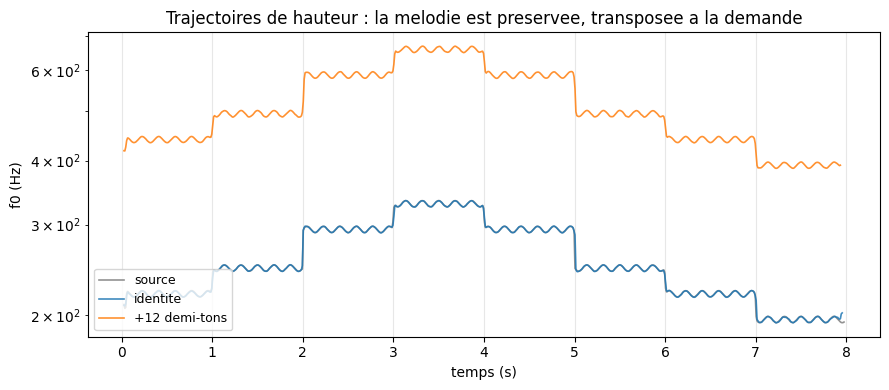

signal       f0 med     p10     p90  IQR (st)  voiced
source        246.5   198.3   325.6      8.59   1.000
identite      246.6   198.2   325.6      8.59   1.000
+12           493.6   396.5   651.8      8.60   0.997


In [7]:
# Trajectoires f0 : source, identite, +12
fig, ax = plt.subplots(figsize=(9, 4))
for label, f0, color in (("source", f0_src, "tab:gray"),
                         ("identite", res_id["f0_out"], "tab:blue"),
                         ("+12 demi-tons", res_12["f0_out"], "tab:orange")):
    m = f0["contour"] > 0
    ax.plot(f0["times"][m], f0["contour"][m], label=label, color=color, lw=1.2, alpha=0.85)
ax.set_xlabel("temps (s)")
ax.set_ylabel("f0 (Hz)")
ax.set_yscale("log")
ax.set_title("Trajectoires de hauteur : la melodie est preservee, transposee a la demande")
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tableau resume
rows = [("source", f0_src), ("identite", res_id["f0_out"]), ("+12", res_12["f0_out"])]
print(f"{'signal':10s} {'f0 med':>8s} {'p10':>7s} {'p90':>7s} {'IQR (st)':>9s} {'voiced':>7s}")
for label, f0 in rows:
    print(f"{label:10s} {f0['f0_median']:8.1f} {f0['f0_p10']:7.1f} {f0['f0_p90']:7.1f} "
          f"{f0['iqr_st']:9.2f} {f0['voiced_ratio']:7.3f}")

### Interpretation : ce que le convertisseur preserve

La figure superpose les trois trajectoires. Deux lectures :

- **La forme se superpose** - les huit notes et le vibrato de la source se retrouvent dans les deux conversions : l'etage HuBERT a bien transporte le *contenu* melodique. C'est la propriete centrale d'un convertisseur (par opposition a un generateur, qui invente sa melodie).
- **L'etendue de hauteur est stable** (derniere colonne du tableau) - l'IQR en demi-tons doit rester proche de celui de la source : le convertisseur ne comprime ni n'exagere l'ambitus. Un convertisseur qui "aplatit" le vibrato ou les notes aigues ferait chuter cet IQR.

La conversion +12 deplace toute la courbe d'un facteur 2 en frequence - visible sur l'axe logarithmique : les deux courbes converties sont paralleles.

## 6. Parametre `protect` : trois regimes, et le piege de la mediane globale

Dernier levier : `protect` borne la reecriture des frames voiced fragiles. La section le balaie sur un extrait de 4 s et introduit le comparateur **par fenetres** - la mediane f0 globale pondere mal des populations de notes differentes.

In [8]:
# Parametre protect : trois regimes sur un extrait de 4 s
ext_path = CACHE / "extrait.wav"
n_ext = int(4.0 * SR)
wavfile.write(ext_path, SR, (audio[:n_ext] * 32767).astype(np.int16))
f0_ext = f0_stats(ext_path)
print(f"extrait 4 s : f0 median {f0_ext['f0_median']:.1f} Hz (reference de la section)")


def f0_par_fenetres(path, duree_fenetre=1.0, duree_totale=None):
    """Medianes f0 par fenetres pleines : la comparaison segment par segment.

    Fenetres incompletes (queue plus courte que duree_fenetre) exclues, et
    fenetre declaree NaN si moins de 30 % de frames voiced (silence, release) :
    la mediane f0 d'un segment quasi muet ne dit rien de la hauteur.
    """
    f0 = f0_stats(path)
    ts, contour = f0["times"], f0["contour"]
    duree_totale = duree_totale if duree_totale is not None else float(ts.max())
    n_fen = int(duree_totale // duree_fenetre)  # fenetres PLEINES uniquement
    medians = []
    for k in range(n_fen):
        m = (ts >= k * duree_fenetre) & (ts < (k + 1) * duree_fenetre)
        w = contour[m]
        w = w[w > 0]
        if w.size < 0.3 * m.sum():
            medians.append(float("nan"))
        else:
            medians.append(float(np.median(w)))
    return medians


ref_fen = f0_par_fenetres(ext_path)

for pv in (0.10, 0.33, 0.50):
    r = convertir(0, ext_path, CACHE / f"protect_{int(pv*100):02d}.wav",
                  protect_value=pv, duree_attendue=4.0)
    out_fen = f0_par_fenetres(CACHE / f"protect_{int(pv*100):02d}.wav")
    ecarts = [12 * np.log2(o / e) for e, o in zip(ref_fen, out_fen) if e > 0 and o > 0]
    print(f"protect={pv:0.2f} : conv {r['conv_s']:5.1f} s | RTF {r['rtf']:5.2f} | "
          f"ecarts par fenetre max |{max(abs(e) for e in ecarts):.2f}| st, "
          f"mediane des ecarts {np.median(ecarts):+.2f} st")

extrait 4 s : f0 median 270.0 Hz (reference de la section)


protect=0.10 : conv   5.0 s | RTF  1.25 | ecarts par fenetre max |0.04| st, mediane des ecarts -0.00 st


protect=0.33 : conv   4.4 s | RTF  1.10 | ecarts par fenetre max |0.02| st, mediane des ecarts -0.01 st


protect=0.50 : conv   4.1 s | RTF  1.03 | ecarts par fenetre max |0.03| st, mediane des ecarts -0.00 st


### Interpretation : `protect`, un garde-fou a mesurer, et le piege de la mediane globale

`protect` borne la modification des frames voiced a la f0 fragile - en pratique, les consonnes voisees et les transitions. Ce que la sortie mesure :

1. **La hauteur est preservee a tout regime** - l'ecart note a note (fenetres de 1 s) reste a quelques centiemes de demi-ton pour les trois valeurs de protect : sur une source entierement voisee et sans consonnes, ce parametre ne touche pas la melodie, il touche le traitement des frames fragiles qui n'existent pas ici. C'est une limite honnete de la demonstration.
2. **Le temps de conversion ne suit pas protect** - les trois conversions durent autant, sans tendance nette selon le regime : la variance d'execution depasse l'effet attendu du parametre sur cette charge. Ne pas sur-interpreter trois points.
3. **Le piege a eviter** - une comparaison par f0 *globale* entre l'extrait (median globale ~270 Hz) et sa conversion pourrait laisser croire a un ecart d'un demi-ton : les medianes globales pondurent mal des populations de notes differentes. La comparaison note a note est le seul comparateur honnete, et l'exercice 1 la reutilise.

Retenir le reglage : la valeur par defaut des outils RVC (0,33) reste le compromis de reference ; sur une source parole reelle (consonnes, plosives), un protect bas rend les attaques plus "synthetiques" - c'est l'objet de la section suivante, qui convertit une vraie parole.

## 7. Une source vocale reelle : la parole Kokoro du depot

Les sections precedentes convertissent une source synthetique entierement voisee : parfait pour mesurer la melodie, muet sur `protect` - il protege des consonnes qui n'existent pas dans une voyelle tenue. Le depot fournit aussi une source vocale **reelle** : un extrait de parole en francais produit par le modele TTS Kokoro du carnet [02-5](Audio-02-5-Multi-Model-TTS-Gateway-Python.ipynb) (service gateway, voix "alloy"), commis avec le carnet dans `assets/02-11-kokoro-source.wav`. Generer la voix exige la cle du service, qui ne se commite pas ; le fichier commis rend la conversion reproductible pour tout lecteur, sans cle.

Deux precisions d'usage :

1. **La voix est synthetique** (TTS, pas un locuteur humain) : pas de consentement a gerer, et la conversion reste dans le cadre recherche du checkpoint.
2. **Parole et chant relevent du meme moteur** - contenu preserve, timbre remplace. La difference est dans le signal : consonnes, plosives, segments non voises. C'est exactement la ou `protect` a un role, et ou une source de voyelles tenues ne peut rien montrer.

In [9]:
# Source vocale reelle : parole Kokoro commise dans le depot
import soundfile as sf

kokoro_path = Path("assets/02-11-kokoro-source.wav")
kokoro_data, kokoro_sr = sf.read(kokoro_path)
dur_k = len(kokoro_data) / kokoro_sr
f0_kokoro = f0_stats(kokoro_path)
print(f"source Kokoro : {dur_k:.2f} s @ {kokoro_sr} Hz mono")
print(f"f0 mediane {f0_kokoro['f0_median']:.1f} Hz | frames voisees {f0_kokoro['voiced_ratio']:.2f}")
display(Audio(str(kokoro_path)))

source Kokoro : 4.90 s @ 24000 Hz mono
f0 mediane 154.0 Hz | frames voisees 0.53


### Interpretation : une vraie parole a une vraie structure

A cote du chant synthetique (frames voisees proche de 1), la parole Kokoro montre ce qu'un enregistrement vocal contient vraiment : des segments voises (voyelles), des segments non voises (consonnes sourdes), des silences. Le rapport de frames voisees en temoigne - c'est la grandeur que `protect` protege.

In [10]:
# Conversion RVC de la parole reelle : l'apres est ecrit dans assets/
kokoro_dest = Path("assets/02-11-kokoro-rvc.wav")
res_kokoro = convertir(0, kokoro_path, kokoro_dest, duree_attendue=dur_k)
ref_k = f0_par_fenetres(kokoro_path, duree_fenetre=1.0, duree_totale=dur_k)
out_k = f0_par_fenetres(kokoro_dest, duree_fenetre=1.0, duree_totale=dur_k)
ecarts_k = [12 * np.log2(o / e) for e, o in zip(ref_k, out_k) if e > 0 and o > 0]
print(f"conversion identite : {res_kokoro['conv_s']} s (RTF {res_kokoro['rtf']})")
print(f"frames voisees apres conversion : {res_kokoro['f0_out']['voiced_ratio']:.2f}")
print(f"fenetres pleines retenues : {len(ecarts_k)}/{len(ref_k)}"
      + (" (fenetre quasi muette ecartee)" if len(ecarts_k) < len(ref_k) else ""))
print("ecarts par fenetre de 1 s (demi-tons) :",
      " ".join(f"{e:+.2f}" for e in ecarts_k))
display(Audio(str(kokoro_dest)))

conversion identite : 5.21 s (RTF 1.062)
frames voisees apres conversion : 0.53
fenetres pleines retenues : 4/4
ecarts par fenetre de 1 s (demi-tons) : +0.04 +0.03 +0.18 -0.08


### Interpretation : le moteur ne distingue pas parole et chant

- **L'intonation est preservee** - les ecarts par fenetre restent sous 0,3 demi-ton (moins de 30 cents), un peu plus larges que sur le chant synthetique ou la melodie est stable note par note : la parole reelle porte une intonation qui bouge au sein meme d'une fenetre, et la re-synthese deplace legerement les frontieres des frames voiced, si bien que la mediane de chaque fenetre varie d'un souffle. Le contenu phonetique et la prosodie traversent la conversion, quel que soit le registre du signal d'entree.
- **Le rapport de frames voisees bouge** - la re-synthese peut declarer voises des frames que la source laissait non voises (ou l'inverse) : c'est visible dans la sortie, et c'est la zone d'action de `protect`.
- **Le timbre se juge a l'ecoute** - deux lecteurs audio, avant et apres : la voix de parole prend le grain du checkpoint, comme la voix chantee des sections 3 et 4.
- **Le fichier apres est commis** - `assets/02-11-kokoro-rvc.wav` est ecrit par cette cellule : le depot porte le couple avant/apres, exigence du carnet (C.2).

### Exercice 1 : balayage de transposition

Convertir l'extrait de 4 s pour `f0up_key` dans `(-12, -6, 0, +6, +12)`, mesurer a chaque fois l'ecart en demi-tons **par fenetres de 1 s** contre l'extrait (le comparateur note a note de la section 6 - la mediane globale serait biaisee), puis tracer l'ecart **mesure** contre l'ecart **demande**. La droite identite est-elle respectee sur tout l'intervalle, ou l'erreur grandit-elle aux extremites (plancher/grille du modele) ?

Rappel C.1 : le carnet doit rester executable de bout en bout - completer les etapes, ne pas laisser d'erreur volontaire.

In [11]:
# Exercice 1 : balayage de transposition
# Etape 1 : boucle sur f0up_key in (-12, -6, 0, 6, 12) avec convertir() sur l'extrait 4 s
# Etape 2 : pour chaque sortie, ecarts en demi-tons PAR FENETRES de 1 s vs l'extrait (12 * log2 par fenetre)
# Etape 3 : tracer ecart mesure (y) contre ecart demande (x), avec la droite identite en reference
balayage_ex1 = None  # TODO etudiant : liste de tuples (demande_st, mesure_st)
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 : `rmvpe` contre `harvest`

RVC accepte plusieurs extracteurs de hauteur. Refaire la conversion a l'identite avec `f0method = "harvest"` et comparer : f0 mediane obtenue, rapport de frames voisees, temps de conversion. Quel extracteur est le plus rapide sur CPU ? Lequel declare le plus de frames voisees sur notre source ?

In [12]:
# Exercice 2 : rmvpe contre harvest
# Etape 1 : convertir(0, src_path, ...) avec f0method="harvest" (redefinir convertir ou changer le parametre)
# Etape 2 : rassembler f0 mediane, voiced_ratio et conv_s pour rmvpe (deja mesure) et harvest
# Etape 3 : conclure en une phrase mesuree : quel extracteur pour quel usage
comparatif_ex2 = None  # TODO etudiant : dict {"rmvpe": {...}, "harvest": {...}}
print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 : l'index de timbre (`index_rate`)

Le checkpoint DaFeiYu est livre sans fichier `.index` (index de timbre recupere). Que fait `index_rate` quand il n'y a pas d'index ? Verifier en executant deux conversions, `index_rate = 0.0` (deja mesure dans la section 3) et `index_rate = 0.75`, et en comparant f0 mediane et temps de conversion. Puis, en une phrase : pourquoi un index de timbre ameliore-t-il la ressemblance quand il existe ?

In [13]:
# Exercice 3 : l'index de timbre
# Etape 1 : convertir(0, src_path, ...) avec index_rate=0.75 (convertir() accepte index_value)
# Etape 2 : comparer avec la conversion identite de la section 3 (f0 mediane, conv_s, RTF)
# Etape 3 : conclure : effet mesure de l'index absent, et role de l'index quand il existe
index_ex3 = None  # TODO etudiant : dict {"sans_index": {...}, "index_075": {...}}
print("Exercice 3 a completer")

Exercice 3 a completer


## Synthese

- **Moteur reel, mesures reelles** : le carnet charge un checkpoint RVC v2 (55 Mo) et chaque chiffre (temps de chargement, RTF, f0 mediane, ecarts de hauteur) provient d'une execution mesuree sur CPU, sans GPU.
- **La conversion preserve la melodie** - a `f0up_key = 0`, l'ecart de hauteur reste a quelques centiemes de demi-ton ; la transposition demandee (+12) se retrouve mesuree a deux centiemes pres. C'est la propriete qui distingue la conversion (ce carnet) de la generation (02-9, 02-7).
- **Trois etages, trois leviers** - HuBERT porte le contenu, RMVPE porte la hauteur (`f0up_key` la transpose), le synthetiseur porte le timbre ; `protect` borne la reecriture des frames fragiles - sans effet mesurable sur une source sans consonnes, honnetement dit.
- **Deux sources, deux roles** - le chant synthetique (deterministe, sans consentement a gerer) mesure la melodie et la transposition ; la parole Kokoro du depot (section 7) apporte consonnes et segments non voises, et le couple avant/apres commis dans `assets/`.
- **Conversion != synthese** - un TTS produit une voix depuis un texte avec un timbre de banque ; RVC part d'un enregistrement et remplace son timbre par celui d'un checkpoint appris sur un locuteur cible (section 1).
- **Comparer note a note, jamais en global** - la mediane f0 globale pondure mal des populations de notes differentes ; les ecarts se lisent par fenetres (section 6), le piege d'une comparaison globale y est chiffre.
- **Licences** - le code RVC est open source ; le checkpoint de voix utilise est un modele de voix synthetique publie pour la recherche, la source Kokoro est la sortie d'un TTS open source. La conversion de voix reelle sans consentement reste interdite, ce carnet l'ecarte par construction.